In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration
sns.set_theme(style="whitegrid")
df = pd.read_csv("supermarket_sales_100k.csv")

print("=== 1. STRUCTURE & TYPES DES DONNÉES ===")
print(f"Dimensions du dataset : {df.shape[0]:,} lignes et {df.shape[1]} colonnes\n")
print(df.info())

print("\n=== 2. APERÇU DES PREMIÈRES LIGNES ===")
display(df.head())

=== 1. STRUCTURE & TYPES DES DONNÉES ===
Dimensions du dataset : 100,233 lignes et 25 colonnes

<class 'pandas.DataFrame'>
RangeIndex: 100233 entries, 0 to 100232
Data columns (total 25 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   ticket_id       100233 non-null  str    
 1   client_id       100233 non-null  str    
 2   age             98595 non-null   float64
 3   sexe            100233 non-null  str    
 4   quartier        99283 non-null   str    
 5   type_client     100233 non-null  str    
 6   date_achat      100233 non-null  str    
 7   heure_achat     100233 non-null  str    
 8   jour_semaine    100233 non-null  str    
 9   mois            100233 non-null  int64  
 10  weekend         100233 non-null  int64  
 11  produit_id      100233 non-null  str    
 12  produit         100233 non-null  str    
 13  categorie       100233 non-null  str    
 14  sous_categorie  100233 non-null  str    
 15  marque          9

,ticket_id,client_id,age,sexe,quartier,type_client,date_achat,heure_achat,jour_semaine,mois,...,marque,rayon_id,rayon,position_rayon,niveau_rayon,quantite,prix_unitaire,prix_total,promotion,taux_reduction
0,T000001,C003177,30.0,F,Chimpunda,Régulier,2025-01-01,08:12,Mercredi,1,...,Élan,R0009,Surgelés,position_02,milieu,1,2.25,2.25,0,0.0
1,T000002,C003552,50.0,F,Kawa,Régulier,2025-01-01,08:18,Mercredi,1,...,Amani,R0003,Crèmerie,position_14,milieu,1,1.25,1.25,0,0.0
2,T000002,C003552,50.0,F,Kawa,Régulier,2025-01-01,08:18,Mercredi,1,...,NutriPlus,R0022,Hygiène & Soins,position_15,milieu,2,2.25,4.05,1,0.1
3,T000003,C000323,58.0,M,Museye,Régulier,2025-01-01,08:33,Mercredi,1,...,Malaika,R0011,Épicerie Sèche,position_18,bas,1,1.75,1.75,0,0.0
4,T000003,C000323,58.0,M,Museye,Régulier,2025-01-01,08:33,Mercredi,1,...,FoodCo,R0011,Épicerie Sèche,position_02,milieu,1,2.50,2.50,0,0.0


In [3]:
print("=== 1. DÉTECTION DES VALEURS MANQUANTES (NULL/NA) ===")
missing_data = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

df_missing = pd.DataFrame({
    'Valeurs Manquantes': missing_data,
    'Pourcentage (%)': missing_percent.round(2)
})
display(df_missing[df_missing['Valeurs Manquantes'] > 0])

if missing_data.sum() == 0:
    print(" Aucune valeur manquante détectée dans le dataset !")

print("\n=== 2. DÉTECTION DES DOUBLONS ===")
doublons_stricts = df.duplicated().sum()
print(f"Lignes doublons strictes : {doublons_stricts}")

# Vérification des doublons logiques (ex: même ticket, même produit répété)
doublons_ticket_produit = df.duplicated(subset=['ticket_id', 'produit_id']).sum()
print(f"Lignes avec même (ticket_id, produit_id) : {doublons_ticket_produit}")

=== 1. DÉTECTION DES VALEURS MANQUANTES (NULL/NA) ===


,Valeurs Manquantes,Pourcentage (%)
age,1638,1.63
quartier,950,0.95
marque,307,0.31



=== 2. DÉTECTION DES DOUBLONS ===
Lignes doublons strictes : 0
Lignes avec même (ticket_id, produit_id) : 0


In [4]:
print("=== CONTROLE DES ANOMALIES DE LOGIQUE METIER ===\n")

# 1. Vérification des prix et quantités
prix_negatifs = df[df['prix_unitaire'] <= 0]
qte_negatives = df[df['quantite'] <= 0]
age_aberrant = df[(df['age'] < 12) | (df['age'] > 100)]

print(f"• Prix unitaires <= 0 : {len(prix_negatifs)} lignes")
print(f"• Quantités <= 0 : {len(qte_negatives)} lignes")
print(f"• Âges suspects (< 12 ou > 100 ans) : {len(age_aberrant)} lignes")

# 2. Vérification de l'exactitude du Prix Total
# Prix total théorique = quantite * prix_unitaire * (1 - taux_reduction)
df['prix_total_calcule'] = df['quantite'] * df['prix_unitaire'] * (1 - df['taux_reduction'])
ecart_prix = np.abs(df['prix_total'] - df['prix_total_calcule'])

incoherence_calcul = df[ecart_prix > 0.01] # Seuil de tolérance pour arrondis
print(f"• Incohérences sur le calcul du prix total : {len(incoherence_calcul)} lignes")

# 3. Vérification des promotions incohérentes
promo_incoherente = df[(df['promotion'] == 0) & (df['taux_reduction'] > 0)]
print(f"• Lignes marquées Hors Promo mais avec Réduction > 0 : {len(promo_incoherente)} lignes")

=== CONTROLE DES ANOMALIES DE LOGIQUE METIER ===

• Prix unitaires <= 0 : 0 lignes
• Quantités <= 0 : 0 lignes
• Âges suspects (< 12 ou > 100 ans) : 0 lignes
• Incohérences sur le calcul du prix total : 0 lignes
• Lignes marquées Hors Promo mais avec Réduction > 0 : 0 lignes


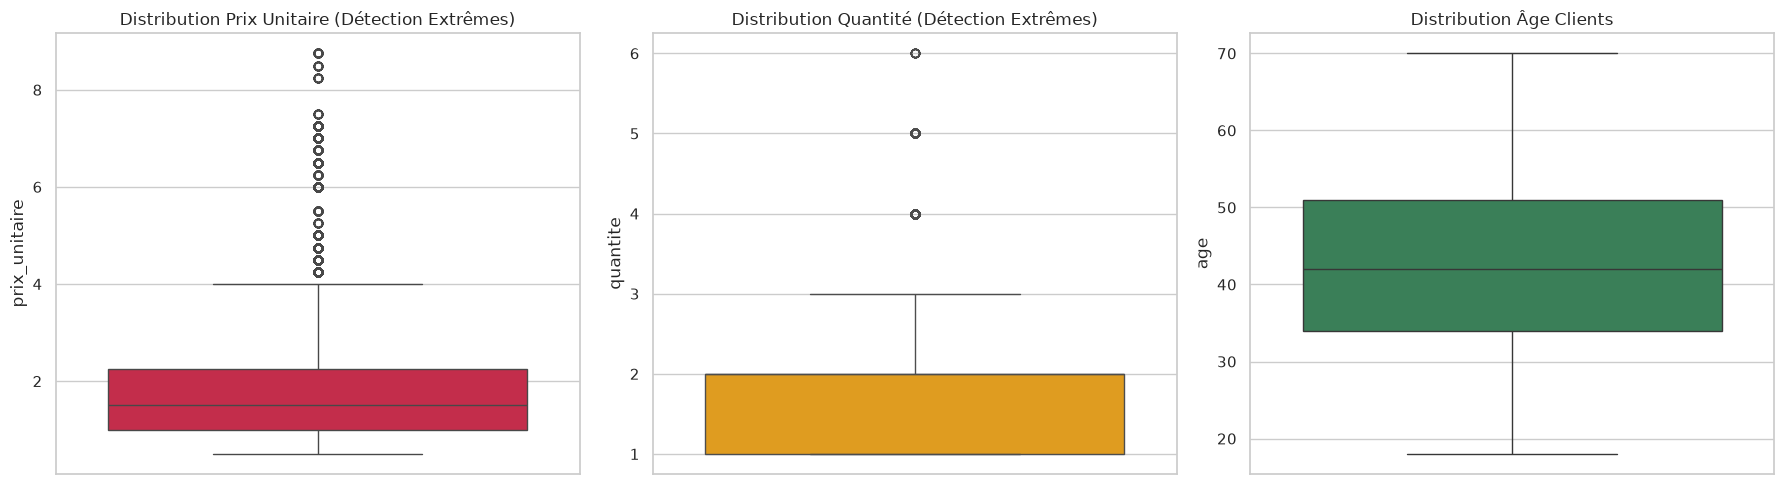

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Boxplot Prix Unitaire
sns.boxplot(y=df['prix_unitaire'], ax=axes[0], color='crimson')
axes[0].set_title("Distribution Prix Unitaire (Détection Extrêmes)")

# Boxplot Quantité
sns.boxplot(y=df['quantite'], ax=axes[1], color='orange')
axes[1].set_title("Distribution Quantité (Détection Extrêmes)")

# Boxplot Âge
sns.boxplot(y=df['age'], ax=axes[2], color='seagreen')
axes[2].set_title("Distribution Âge Clients")

plt.tight_layout()
plt.show()

In [6]:
# Copie de sécurité
df_clean = df.copy()

print("=== DEBUT DU NETTOYAGE DES DONNEES ===")

# 1. Suppression des doublons stricts s'il y en a
df_clean = df_clean.drop_duplicates()

# 2. Correction/Filtrage des valeurs aberrantes ou incohérentes
df_clean = df_clean[df_clean['prix_unitaire'] > 0]
df_clean = df_clean[df_clean['quantite'] > 0]
df_clean = df_clean[(df_clean['age'] >= 12) & (df_clean['age'] <= 100)]

# 3. Recalcul propre du Prix Total pour éliminer les erreurs d'arrondi
df_clean['prix_total'] = (df_clean['quantite'] * df_clean['prix_unitaire'] * (1 - df_clean['taux_reduction'])).round(2)

# 4. Homogénéisation des dates et heures
df_clean['date_achat'] = pd.to_datetime(df_clean['date_achat'])
df_clean['heure_num'] = df_clean['heure_achat'].astype(str).str.split(':').str[0].astype(int)

# 5. Nettoyage des colonnes temporaires
if 'prix_total_calcule' in df_clean.columns:
    df_clean.drop(columns=['prix_total_calcule'], inplace=True)

# Sauvegarde du dataset propre
df_clean.to_csv("dataset_cleaned.csv", index=False)

print(f"\n Nettoyage terminé avec succès !")
print(f"Lignes initiales : {len(df):,} | Lignes conservées : {len(df_clean):,}")
print("Fichier sauvegardé sous le nom 'dataset_cleaned.csv'")

=== DEBUT DU NETTOYAGE DES DONNEES ===

 Nettoyage terminé avec succès !
Lignes initiales : 100,233 | Lignes conservées : 98,595
Fichier sauvegardé sous le nom 'dataset_cleaned.csv'


In [7]:
df.shape

(100233, 26)